Desarrolo del modelo Random Forest

## Librerias y Configuración

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, GradientBoostingRegressor)
from sklearn.manifold import MDS
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("../data/df_final.csv")

numeric_features = [
    "age",
    "baseline_bmi",
    "baseline_charlson_comorbidity_index",
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "n_meds",
    "n_high_risk_meds",
    "serum_creatinine_mg_dl",
    "hemoglobin_g_dl",
    "spo2_percent",
    "respiratory_rate_bpm",
    "heart_rate_bpm",
    "systolic_bp_mmhg",
    "white_blood_cell_count",
    "blood_glucose_mg_dl"
]

categoric_features = [
    "discharge_disposition",
    "disease_category",
    "disease_severity",
    "department",
    "admission_urgency",
    "encounter_type",
    "primary_insurance_provider",
    "socioeconomic_tier",
    "residential_zone",
    "smoker_status",
    "gender",
    "procedure_complexity",
    "hospital_acquired_infection"   
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)


X shape: (13214, 30)
y shape: (13214,)


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
    300
    ,random_state=42
    ,n_jobs=1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
    
cv_results = cross_validate(
    random_forest,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

In [4]:
print("RESULTADOS CROSS-VALIDATION 5 FOLDS")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric:12} - Media: {scores.mean():.4f}")


random_forest.fit(X_train, y_train)

y_pred = random_forest.predict(X_test)
y_proba = random_forest.predict_proba(X_test)[:, 1]

print("PREDICCIONES")
print(classification_report(y_test, y_pred, target_names=["No reingreso", "Reingreso"]))
print(f"AUC-ROC Test: {roc_auc_score(y_test, y_proba):.4f}")

RESULTADOS CROSS-VALIDATION 5 FOLDS
accuracy     - Media: 0.7332
precision    - Media: 0.6496
recall       - Media: 0.4171
f1           - Media: 0.5078
roc_auc      - Media: 0.7765
PREDICCIONES
              precision    recall  f1-score   support

No reingreso       0.75      0.89      0.82      1770
   Reingreso       0.65      0.41      0.51       873

    accuracy                           0.73      2643
   macro avg       0.70      0.65      0.66      2643
weighted avg       0.72      0.73      0.71      2643

AUC-ROC Test: 0.7854


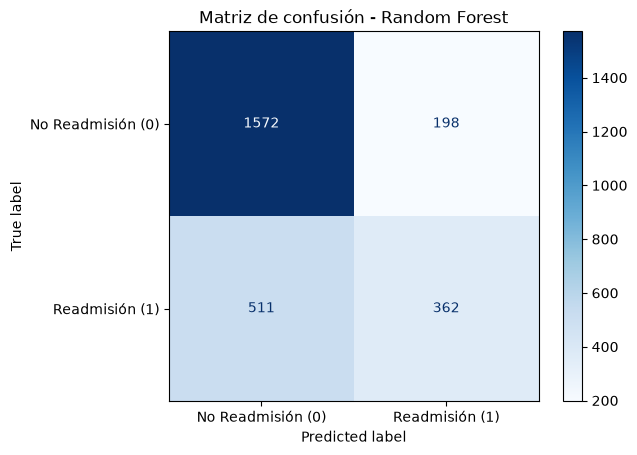

In [5]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmisión (0)", "Readmisión (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Random Forest")
plt.show()

##
Conclusiones

- Con la CV de 5 partes sobre el entrenamiento, se observo que el modelo no memoriza los datos y que el resultado en prueba es confiable
- Acierta un 73 %, mientras que decir siempre “no reingresa” acertaría el 67 % (1770). Son 6 puntos más
- El AUC de 0.79 indica una capcidad aceptable para distinguir a los pacientes que reingresan de los que no 
 - El modelo detecta 4 de cada 10 reingresos reales